In [1]:
import numpy as np
import pandas as pd

In [ ]:
dataset_path = 'dataset'

In [23]:
import os

data = {}

for subdir in os.listdir(dataset_path):
    folder_path = os.path.join(dataset_path, subdir)
    if os.path.isdir(folder_path):
        data[subdir] = []
        for file in os.listdir(folder_path):
            if file.lower().endswith((".jpg", ".jpeg", ".png")):
                data[subdir].append(os.path.join(folder_path, file))

for k, v in data.items():
    print(f"{k}: {len(v)} images")

ai: 542 images
real: 436 images


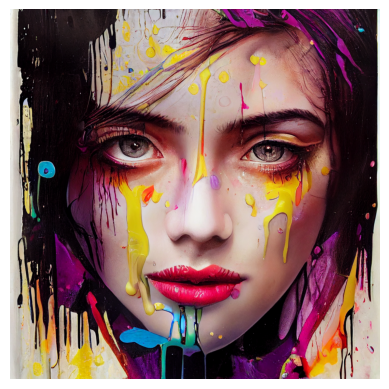

In [24]:
import matplotlib.pyplot as plt
import cv2

img_path = data["ai"][6]

img = cv2.imread(img_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(img)
plt.axis("off")
plt.show()


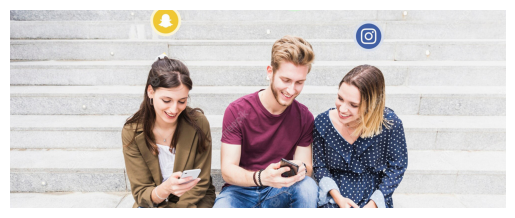

In [25]:
import matplotlib.pyplot as plt
import cv2

img_path = data["real"][10]

img = cv2.imread(img_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(img)
plt.axis("off")
plt.show()


In [26]:
import cv2
import numpy as np
from sklearn.model_selection import train_test_split

# image size for resizing
IMG_SIZE = (128, 128)

X = []
y = []

label_map = {label: idx for idx, label in enumerate(data.keys())}  # {"real": 0, "ai": 1}

for label, paths in data.items():
    for path in paths:
        img = cv2.imread(path)
        if img is None:
            continue  # skip corrupted images
        img = cv2.resize(img, IMG_SIZE)  # resize
        img = img / 255.0                # normalize [0,1]
        X.append(img)
        y.append(label_map[label])

# convert to numpy arrays
X = np.array(X, dtype="float32")
y = np.array(y, dtype="int")

print("X shape:", X.shape)   # (num_images, 128, 128, 3)
print("y shape:", y.shape)   # (num_images,)

# train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train size:", X_train.shape[0])
print("Test size:", X_test.shape[0])


X shape: (978, 128, 128, 3)
y shape: (978,)
Train size: 782
Test size: 196


In [64]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D

# -------- Base Model: MobileNetV2 --------
base_model = MobileNetV2(include_top=False, 
                         weights='imagenet', 
                         input_shape=(128,128,3))

base_model.trainable = True   # freeze backbone
for layer in base_model.layers[:-20]:   # last 20 layers trainable
    layer.trainable = False
# -------- Sequential Model --------
model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(128, activation='relu'),
    Dense(2, activation='softmax')
])

# -------- Compile --------
model.compile(optimizer=tf.keras.optimizers.Adam(1e-4), 
              loss='sparse_categorical_crossentropy', 
              metrics=['accuracy'])

model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,619,074 (9.99 MB)

 Trainable params: 1,567,170 (5.98 MB)

 Non-trainable params: 1,051,904 (4.01 MB)

In [65]:
model.fit(X_train, y_train, epochs=10)

Epoch 1/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 17s 290ms/step - accuracy: 0.5460 - loss: 0.7983
Epoch 2/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 9s 348ms/step - accuracy: 0.7340 - loss: 0.5229
Epoch 3/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 8s 327ms/step - accuracy: 0.8517 - loss: 0.3760
Epoch 4/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 7s 285ms/step - accuracy: 0.8913 - loss: 0.2775
Epoch 5/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 7s 285ms/step - accuracy: 0.9271 - loss: 0.2199
Epoch 6/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 7s 294ms/step - accuracy: 0.9655 - loss: 0.1493
Epoch 7/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 10s 380ms/step - accuracy: 0.9719 - loss: 0.1128
Epoch 8/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 8s 318ms/step - accuracy: 0.9821 - loss: 0.0810
Epoch 9/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 8s 304ms/step - accuracy: 0.9885 - loss: 0.0621
Epoch 10/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 8s 301ms/step - accuracy: 0.9910 - loss: 0.0467


In [66]:
os.listdir('./test_images')

['fk1.jpg', 'fk2.jpg', 'fk3.jpg', 'fk4.jpg', 'fk5.jpg']

In [67]:
IMG_SIZE = (128, 128)

test_images = []

for path in os.listdir('./test_images'):
    img_path = os.path.join('./test_images', path)
    img = cv2.imread(img_path)
    if img is None:
        continue  # skip corrupted images
    img = cv2.resize(img, IMG_SIZE)  # resize
    img = img / 255.0                # normalize [0,1]
    test_images.append(img)
print(len(test_images))
# convert to numpy arrays
test_images = np.array(test_images, dtype="float32")

test_images.shape

5


(5, 128, 128, 3)

In [68]:
model.evaluate(X_test, y_test)

7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 195ms/step - accuracy: 0.8112 - loss: 0.5683


[0.5683020949363708, 0.8112244606018066]

In [69]:
preds = model.predict(test_images)
predicted_labels = np.argmax(preds, axis=1)


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


In [70]:
predicted_labels

array([1, 1, 1, 1, 1])

In [71]:
model.save('cnn_model.h5')